Name Taherunnesa Rahi

Labpartner(s)

In [1]:
#import statements go here


# Class 7.2

Today your assignment is the rest of the pandas unit and to catch up and think about your project topic, which is due by Sunday 10/13.

**W.1** Implement a function that takes as input three variables, and returns the largest of the three. Do this without using the Python max() function.

The goal of this exercise is to think about some internals that Python normally takes care of for us. All you need is some variables and if statements.

In [1]:
def largest(a, b, c):
    largest = a

    if b > largest:
        largest = b

    if c > largest:
        largest = c

    return largest

a = float(input("Enter the first number: "))
b = float(input("Enter the second number: "))
c = float(input("Enter the third number: "))

print("The largest number is:", largest(a, b, c))

Enter the first number:  8
Enter the second number:  9
Enter the third number:  6


The largest number is: 9.0


# Lecture 7.2

### Agenda:

- Questions
- Tropical Tidbits
- Movie project!

### Questions

For our project this week, I am unleashing you use LLMs for coding, and specifically how to make a series of images into a playable movie. For example, say you have a series of daily HYCOM SST plots, and you want to animate this, how would you do it? We'll strategize more in class about how to accomplish this as a team and with the help of ChatGPT, Claude, or whatever, and hopefully come up with a few different workflows you can share. 

# Lab 7.2

**E.0** Complete the previous labs if you are behind.

**E.1** Complete Data Manipulation with Pandas Ch 3-4 in datacamp.

**E.2** Make notes for yourself on progamming tecniques and commands you learned in the datacamp chapter above, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.

Subset temperatures using square brackets
print(temperatures[temperatures["city"].isin(cities)])

Subset temperatures_ind using .loc[]
print(temperatures_ind.loc[cities])


Sort by the city level
print(temperatures_ind.sort_index(level="city"))

 Sort by ascending country, then descending city
print(temperatures_ind.sort_index(
    level=["country", "city"],
    ascending=[True, False]
)) 




Using pivot table is a way of calculating group summary statistics

The first argument is the column name containing values to aggregate. The index argument lists the columns to group by and display in rows, and the columns argument lists the columns to group by and display in columns.

Print mean weekly_sales by department and type; fill missing values with 0
print(sales.pivot_table(
    values="weekly_sales",
    index="department",
    columns="type",
    fill_value=0
))

#scatterplot
avocados.plot(
    kind="scatter",
    x="nb_sold",
    y="avg_price",
    title="Number of avocados sold vs. average price"
)

filling missing value with zero
dogs.fillna(0)


Check individual values for missing values
print(avocados_2016.isna())

Check each column for missing values
print(avocados_2016.isna().any())

Bar plot of missing values by variable
avocados_2016.isna().sum().plot(kind="bar")



Remove rows with missing values
avocados_complete = avocados_2016.dropna()



**E.3** For this week's project, find a series of images you want to animate. This can be model output, a series of other plots, whatever you want. Everyone needs to pick their own dataset. Work together and share ideas for different ways to make these movies, and work with an LLM to help you figure this out. Next week on Monday or Wednesday you will present your movie and tell us how you made it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import cartopy.crs as ccrs
import cartopy.feature as cfeature

I made the video of how water temperature changed with depth (surface to 200 meters) in the Gulf of Mexico on my birthday, November 3, 2025. 

In [2]:
import xarray as xr

rahi_data = xr.open_dataset(
    "028_archv.2025_307_00_3z.nc",
    decode_times=False
)

rahi_data

<xarray.Dataset> Size: 3GB
Dimensions:     (MT: 1, Depth: 40, Latitude: 1537, Longitude: 2101)
Coordinates:
  * MT          (MT) float64 8B 4.56e+04
    Date        (MT) float64 8B ...
  * Depth       (Depth) float32 160B 0.0 2.0 4.0 6.0 ... 3e+03 4e+03 5e+03
  * Latitude    (Latitude) float32 6kB 18.09 18.1 18.11 ... 31.94 31.95 31.96
  * Longitude   (Longitude) float32 8kB -98.0 -97.99 -97.98 ... -77.01 -77.0
Data variables:
    u           (MT, Depth, Latitude, Longitude) float32 517MB ...
    v           (MT, Depth, Latitude, Longitude) float32 517MB ...
    w_velocity  (MT, Depth, Latitude, Longitude) float32 517MB ...
    water_temp  (MT, Depth, Latitude, Longitude) float32 517MB ...
    salinity    (MT, Depth, Latitude, Longitude) float32 517MB ...
Attributes:
    Conventions:  CF-1.0
    title:        HYCOM
    source:       HYCOM archive file
    experiment:   02.8
    history:      archv2ncdf3z

In [3]:
print(rahi_data["Depth"].values)

[0.00e+00 2.00e+00 4.00e+00 6.00e+00 8.00e+00 1.00e+01 1.20e+01 1.50e+01
 2.00e+01 2.50e+01 3.00e+01 3.50e+01 4.00e+01 4.50e+01 5.00e+01 6.00e+01
 7.00e+01 8.00e+01 9.00e+01 1.00e+02 1.25e+02 1.50e+02 2.00e+02 2.50e+02
 3.00e+02 3.50e+02 4.00e+02 5.00e+02 6.00e+02 7.00e+02 8.00e+02 9.00e+02
 1.00e+03 1.25e+03 1.50e+03 2.00e+03 2.50e+03 3.00e+03 4.00e+03 5.00e+03]


In [4]:
print(rahi_data["Depth"].values.astype(int))

[   0    2    4    6    8   10   12   15   20   25   30   35   40   45
   50   60   70   80   90  100  125  150  200  250  300  350  400  500
  600  700  800  900 1000 1250 1500 2000 2500 3000 4000 5000]


In [21]:
temp_data = rahi_data.sel(Depth=slice(0, 200))

x = temp_data.Longitude
y = temp_data.Latitude
depths = temp_data.Depth.values

lon_min = rahi_data.Longitude.min()
lon_max = rahi_data.Longitude.max()
lat_min = rahi_data.Latitude.min()
lat_max =  rahi_data.Latitude.max()



In [20]:
print(temp_data["water_temp"].min().item())
print(temp_data["water_temp"].max().item())

9.280460357666016
30.596628189086914


In [24]:
# Same temperature bands for every frame
step = np.arange(0, 33, 2)

land_50m = cfeature.NaturalEarthFeature(
    'physical', 'land', '50m',
    edgecolor='black',
    facecolor='lightpink'
)

Text(0.5, 1.0, 'November 3, 2025 — Depth: 0 m')

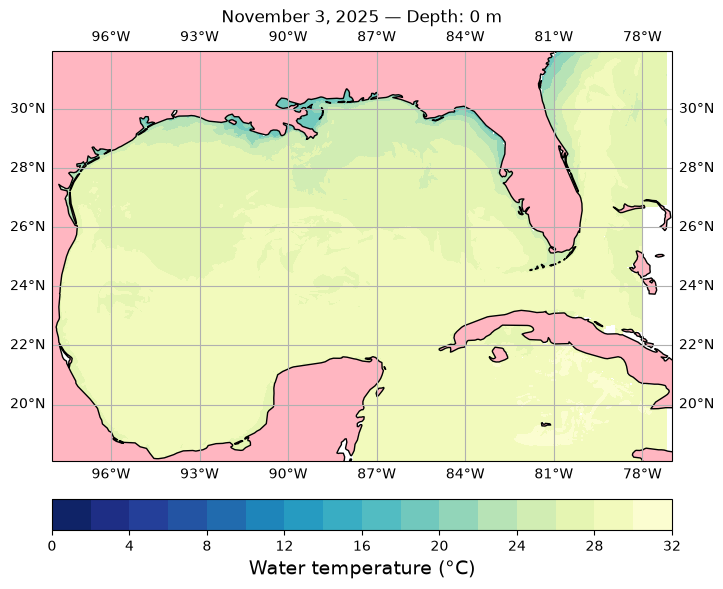

In [33]:
#created a plot and colorbar.later colorbar will stay
fig, ax = plt.subplots(
    figsize=(8, 10),
    subplot_kw=dict(projection=ccrs.PlateCarree())
)

ax.set_extent([lon_min, lon_max, lat_min, lat_max])
ax.add_feature(land_50m)

var = temp_data.water_temp[0, 0, :, :]

p = ax.contourf(
    x, y, var,
    transform=ccrs.PlateCarree(),
    cmap='YlGnBu_r',
    levels=step
)

cbar = plt.colorbar(p, orientation='horizontal', pad=0.05)
cbar.set_label('Water temperature (°C)', size=14)

ax.gridlines(draw_labels=True)
ax.set_title('November 3, 2025 — Depth: 0 m')

In [34]:
#defing the function here 
def update(frame):
    # Clear the previous map
    ax.clear()

    # Draw the map again
    ax.set_extent([lon_min, lon_max, lat_min, lat_max])
    ax.add_feature(land_50m)

    # Select temperature at this depth
    var = temp_data.water_temp[0, frame, :, :]

    p = ax.contourf(
        x, y, var,
        transform=ccrs.PlateCarree(),
        cmap='YlGnBu_r',
        levels=step)

    ax.gridlines(draw_labels=True)

    ax.set_title(
        f'Gulf of Mexico Water Temperature\n'
        f'November 3, 2025 — Depth: {depths[frame]:g} m'
    )

In [37]:
movie = animation.FuncAnimation(  #animation.FuncAnimation() is a Matplotlib tool that makes an animation by repeatedly calling a function.
    fig,
    update,
    frames=len(depths),
    interval=700,
    blit=False #blit=False means redraw the whole plot for each frame.
)

movie.save(
    'Gulf_Temperature_0_to_200m.gif',
    writer=animation.PillowWriter(fps=1.5),
    dpi=100
)

plt.close(fig)

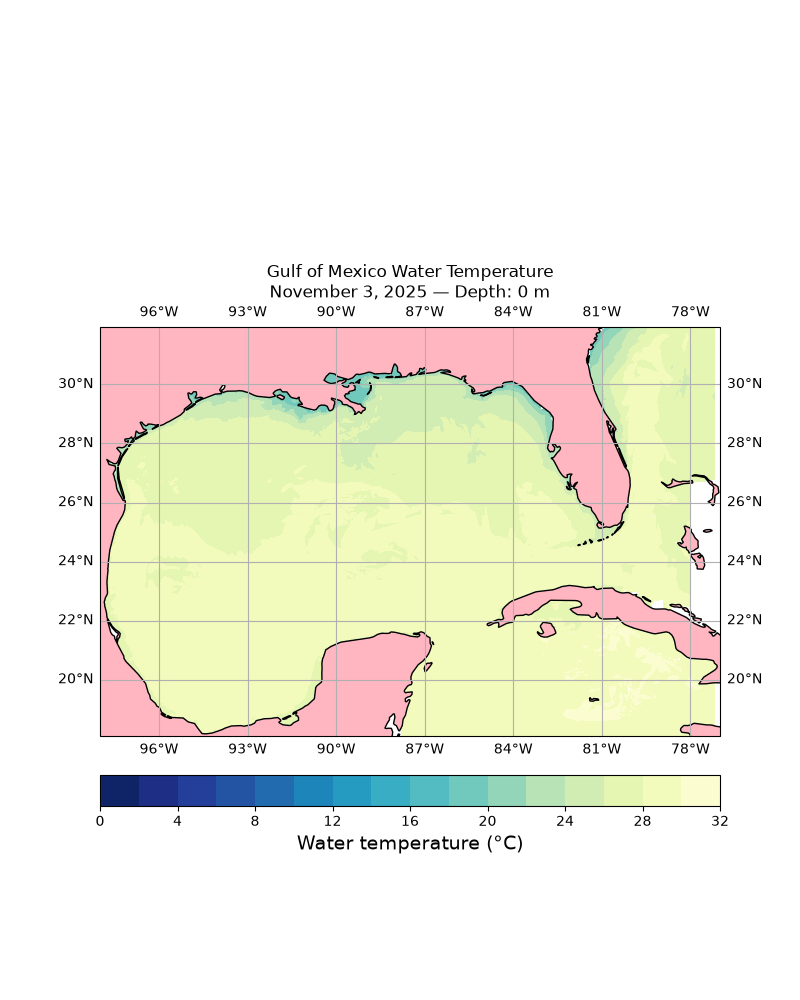

In [38]:
from IPython.display import Image, display

display(Image(filename="Gulf_Temperature_0_to_200m.gif"))